# Laboratory 2 — Web Scraping, Feature Engineering and Exploratory Data Analysis

**Course:** Introduction to Artificial Intelligence (AI–101L) · **Instructor:** Dr. Muhammad Awais
**Duration:** 3 hours · **Block:** Phase A — Environment and Data · **Mapped CLO:** CLO–2

---

## Learning Objectives

On completion of this laboratory you will be able to:

1. Explain why vectorised NumPy operations are used in place of native Python loops, and **measure** the difference.
2. Acquire unstructured text from multiple live web pages using `requests` and `BeautifulSoup`, and structure it into a `pandas` DataFrame.
3. Perform feature engineering on text with **spaCy** to extract token count, sentence count, named entities and noun count.
4. Compute sentiment **polarity** and **subjectivity** with **TextBlob**.
5. Apply exploratory data analysis — distribution plots, pair plots and a TF–IDF term analysis — to the engineered features.

## Background

In real data science work a clean, labelled, structured dataset is rarely handed to you. **It has
to be built.** This laboratory implements the first complete pipeline of the course:

```
Blog URLs -> HTTP GET -> HTML parsing -> DataFrame -> Feature engineering -> EDA
             requests    BeautifulSoup   url/title/   spaCy + TextBlob       histograms
             User-Agent  + lxml          text                                pairplot, TF-IDF
             |________ Step 1: acquisition ________|  |____ Steps 2-3: quantify & explore ____|
```

> **Instructor note.** Live websites change. If a selector stops matching, that *is* the lesson —
> Exercise 1 asks students to diagnose exactly this. Have a cached copy of `articles.csv` ready
> so that Sections 4–5 can proceed even if the network is unavailable.

### Justification of libraries and tools

| Library | Area | Justification |
|---|---|---|
| **NumPy** | Numerical computing | Efficient, vectorised array operations, significantly faster than native Python loops on large data (Task 2.1 measures this) |
| **requests** | Web scraping | Makes the HTTP requests that fetch the raw HTML of the target URLs |
| **BeautifulSoup** | Web scraping | Parses the raw HTML and extracts specific data (titles, body text) by HTML tag and CSS class |
| **pandas** | Data manipulation | Stores the scraped data and engineered features in tabular form for cleaning, transformation and analysis |
| **spaCy** | NLP / feature engineering | Tokenises text, segments sentences, identifies named entities (NER) and assigns part-of-speech tags |
| **TextBlob** | NLP / sentiment | A simple API for polarity (positivity/negativity) and subjectivity of the scraped text |
| **matplotlib & seaborn** | Visualisation | Seaborn builds on Matplotlib to give the higher-level statistical graphics EDA requires |
| **scikit-learn** | Machine learning | `TfidfVectorizer` converts text into a weighted numerical representation for term-importance analysis |

---
# Task 2.1 — Setup, and why NumPy exists

Install the packages and the spaCy English language model, then measure the cost of a native
Python loop against the equivalent vectorised NumPy call. **Record both timings in your report.**

In [1]:
# Installation of required libraries (run once per environment)
!pip install requests beautifulsoup4 lxml pandas spacy matplotlib seaborn textblob

# Download the small English language model for spaCy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 19.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


> ### Troubleshooting: `ForwardRef._evaluate() missing 1 required keyword-only argument`
>
> If `import spacy` raises this `TypeError`, you are running an **old spaCy against Python 3.12**.
> spaCy's schema module still uses the legacy `pydantic.v1` API, which Python 3.12 broke.
>
> Two fixes, in order of preference:
>
> 1. **Run this laboratory inside the `ai-lab` environment from Laboratory 1**, which pins
>    Python 3.11:
>    ```
>    conda activate ai-lab
>    ```
> 2. Or upgrade in place:
>    ```
>    pip install -U "spacy>=3.7.5" "pydantic>=2.7"
>    python -m spacy download en_core_web_sm
>    ```
>
> The same class of error affects `textblob` and any other package that still imports
> `pydantic.v1`. **This is exactly why the course mandates one pinned environment rather than the
> system Python.**

In [2]:
import numpy as np
import time

size = 10_000_000
data = np.random.rand(size)

# --- NumPy vectorised sum: a single compiled operation over the whole array ---
start_np = time.time()
np_sum = np.sum(data)
end_np = time.time()

# --- Manual Python loop: ten million interpreted iterations ------------------
start_py = time.time()
manual_sum = 0
for val in data:
    manual_sum += val
end_py = time.time()

print(f"NumPy Sum : {np_sum:.2f} | Time: {end_np - start_np:.5f} sec")
print(f"Manual Sum: {manual_sum:.2f} | Time: {end_py - start_py:.5f} sec")
print()
print(f"NumPy is {(end_py - start_py) / (end_np - start_np):.0f}x faster on this machine.")

NumPy Sum : 4999262.42 | Time: 0.00655 sec
Manual Sum: 4999262.42 | Time: 2.58943 sec

NumPy is 395x faster on this machine.


> ### Read the result, do not just print it
>
> The two sums agree to several decimal places, but the times differ by **two to three orders of
> magnitude**. Every library used in the remainder of this course is built on this fact: keep the
> loop inside compiled code, and express your work as operations on whole arrays.

---
# Task 2.2 — Web scraping and data acquisition

Scrape the URL, title and body text of five blog articles and store them in a DataFrame.

**Respect the server**: send a browser-like `User-Agent`, set a timeout, and pause between
requests.

| Code | Explanation |
|---|---|
| `headers = {...}` | Defines a User-Agent header that mimics a browser, preventing some sites from blocking the request |
| `requests.get(url, ...)` | Executes the HTTP GET request for the current URL |
| `BeautifulSoup(res.content, 'lxml')` | Parses the raw HTML with the fast `lxml` parser |
| `soup.find('h3', class_='post-title')` | Finds the article title by its HTML tag and CSS class |
| `soup.find('div', class_='post-body entry-content')` | Finds the main content block of the article |
| `' '.join(p.get_text(strip=True) ...)` | Extracts the text of every `<p>` tag inside the content block and joins it |
| `pd.DataFrame(articles)` | Creates the final DataFrame of scraped records |

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

urls = [
    'https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html',
    'https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html',
    'https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html',
    'https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html',
    'https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html',
]

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

# Exercise 1: add two URLs of our own. We take the two newest articles from
# the Machine Learning Mastery feed (a feed is a list of the latest posts).
try:
    feed = requests.get("https://machinelearningmastery.com/blog/feed/", headers=headers, timeout=15)
    items = BeautifulSoup(feed.content, "xml").find_all("item")
    extra_urls = [i.find("link").get_text(strip=True) for i in items[:2]]
except Exception as e:
    print("[WARN] Could not read the feed for the 2 extra URLs:", e)
    extra_urls = []
urls += extra_urls
print("Extra URLs added:", extra_urls)

articles = []

for url in urls:
    try:
        # Fetch the page content
        res = requests.get(url, headers=headers, timeout=10)
        res.raise_for_status()
        soup = BeautifulSoup(res.content, 'lxml')

        # Extract Title
        title = soup.find('h3', class_='post-title') or soup.find('h1')
        title = title.get_text(strip=True) if title else soup.title.get_text(strip=True)

        # Extract Body Text
        content_div = soup.find('div', class_='post-body entry-content')
        if not content_div:
            # Fallback for other blog layouts (Exercise 1)
            content_div = soup.find('article') or soup.find('main')
        if not content_div:
            print(f"[SKIP] No content block found: {url}")
            continue

        paragraphs = content_div.find_all('p')
        text = ' '.join(p.get_text(strip=True) for p in paragraphs)

        # FIX for Exercise 1: some posts have no <p> tags,
        # so take all the text from the block instead
        if len(text) < 100:
            text = content_div.get_text(' ', strip=True)

        # Skip short articles for quality control
        if len(text) > 100:
            articles.append({'url': url, 'title': title, 'text': text})
        else:
            print(f"[SKIP] Too short: {url}")

        time.sleep(1)   # Be polite to the server
    except Exception as e:
        print(f"[ERROR] {url} -> {e}")

df = pd.DataFrame(articles)
print(f"\nScraped {len(df)} of {len(urls)} articles.")
df.head()


Extra URLs added: ['https://machinelearningmastery.com/how-to-train-your-own-decision-model-like-jev-using-unsloth/', 'https://machinelearningmastery.com/choosing-an-llm-inference-optimization-technique-a-decision-tree-approach/']

Scraped 7 of 7 articles.


,url,title,text
0,https://techncruncher.blogspot.com/2025/01/top...,Top 10 AI Tools That Will Transform Your Conte...,Looking to level up your content creation gam...
1,https://techncruncher.blogspot.com/2023/12/lim...,"LimeWire AI Studio Review 2023: Details, Prici...",In the rapidly advancing landscape of AI tech...
2,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too..."
3,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...
4,https://techncruncher.blogspot.com/2022/09/cj-...,Beginner Guide to CJ Affiliate (Commission Jun...,Image by vectorjuice on Freepik In this CJ Aff...


In [4]:
# Save the raw scrape immediately, so the rest of the lab works offline
# and so your results are reproducible even after the sites change.
if not df.empty:
    df.to_csv("articles_raw.csv", index=False)
    print("Saved articles_raw.csv")
else:
    # Fallback: load a previously saved scrape
    df = pd.read_csv("articles_raw.csv")
    print("Network scrape empty -- loaded the cached articles_raw.csv instead.")

print(df.shape)

Saved articles_raw.csv
(7, 3)


---
# Task 2.3 — Linguistic feature engineering with spaCy

Feature engineering **quantifies the qualitative text**. The `extract_features` function derives
four metrics per article:

| Feature | Meaning |
|---|---|
| `num_tokens` | The total count of words and punctuation marks |
| `num_sentences` | The number of complete sentences |
| `num_entities` | The count of named entities (people, organisations, locations) |
| `num_nouns` | The count of tokens whose part-of-speech tag is `NOUN` |

In [5]:
import spacy
import pandas as pd

# Loads the trained spaCy English model: tokenizer, POS tagger and NER
nlp = spacy.load("en_core_web_sm")

def extract_features(text):
    """Process text with spaCy and extract four linguistic features."""
    doc = nlp(text)
    return pd.Series({
        'num_tokens':    len(doc),                                   # tokens
        'num_sentences': len(list(doc.sents)),                       # sentences
        'num_entities':  len(doc.ents),                              # named entities
        'num_nouns':     len([t for t in doc if t.pos_ == 'NOUN'])   # nouns
    })

if not df.empty:
    features = df['text'].apply(extract_features)
    df = pd.concat([df, features], axis=1)

    # A simple non-spaCy feature for comparison
    df['title_length'] = df['title'].apply(len)

    print("Features extracted successfully.")
    display(df[['title', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns']].head())
else:
    print("No articles found for feature extraction.")

Features extracted successfully.


,title,num_tokens,num_sentences,num_entities,num_nouns
0,Top 10 AI Tools That Will Transform Your Conte...,1188,47,24,321
1,"LimeWire AI Studio Review 2023: Details, Prici...",1723,65,103,420
2,Top 10 AI Tools in 2023 That Will Make Your Li...,1480,52,39,331
3,Top 10 AI Content Generator & Writer Tools in ...,1319,63,89,271
4,Beginner Guide to CJ Affiliate (Commission Jun...,1822,102,79,391


In [6]:
# Inspect WHAT spaCy actually found, not just how many.
# Reading the entities is how you learn whether the feature is meaningful.

doc = nlp(df['text'].iloc[0][:1500])

print("First 15 named entities in article 1:\n")
for ent in list(doc.ents)[:15]:
    print(f"  {ent.text:<35} {ent.label_:<12} ({spacy.explain(ent.label_)})")

First 15 named entities in article 1:

  2025                                DATE         (Absolute or relative dates or periods)
  AI                                  GPE          (Countries, cities, states)
  10                                  CARDINAL     (Numerals that do not fall under another type)
  AI                                  GPE          (Countries, cities, states)
  2025                                DATE         (Absolute or relative dates or periods)
  AI                                  GPE          (Countries, cities, states)
  Dive Into the Top 10                WORK_OF_ART  (Titles of books, songs, etc.)
  2025                                DATE         (Absolute or relative dates or periods)
  Magic Studio                        PERSON       (People, including fictional)
  AI                                  ORG          (Companies, agencies, institutions, etc.)


## Sentiment features with TextBlob

TextBlob provides a quick way to calculate two independent scores:

- **Polarity** runs from $-1.0$ (strongly negative) through $0.0$ (neutral) to $+1.0$ (strongly positive).
- **Subjectivity** runs from $0.0$ (a purely objective statement of fact) to $1.0$ (a purely personal opinion).

In [7]:
from textblob import TextBlob

def get_sentiment(text):
    """Polarity in [-1, 1]; subjectivity in [0, 1]."""
    blob = TextBlob(text)
    return pd.Series({
        'sentiment_polarity':     blob.sentiment.polarity,
        'sentiment_subjectivity': blob.sentiment.subjectivity
    })

if not df.empty:
    sentiment_features = df['text'].apply(get_sentiment)
    df = pd.concat([df, sentiment_features], axis=1)

    print("Sentiment features extracted successfully.\n")
    display(df[['title', 'sentiment_polarity', 'sentiment_subjectivity']])

Sentiment features extracted successfully.



,title,sentiment_polarity,sentiment_subjectivity
0,Top 10 AI Tools That Will Transform Your Conte...,0.229493,0.583603
1,"LimeWire AI Studio Review 2023: Details, Prici...",0.219387,0.573587
2,Top 10 AI Tools in 2023 That Will Make Your Li...,0.197417,0.436441
3,Top 10 AI Content Generator & Writer Tools in ...,0.214853,0.564907
4,Beginner Guide to CJ Affiliate (Commission Jun...,0.253833,0.480973
5,How to Train Your own Decision Model like Jev ...,0.136148,0.485422
6,Choosing an LLM Inference Optimization Techniq...,0.125479,0.426420


> ### Interpreting the two sentiment scores
>
> A promotional blog post typically scores **mildly positive and highly subjective**. Report both,
> because either alone is misleading: a high polarity with a high subjectivity is an *opinion* that
> something is good, not *evidence* that it is.

In [8]:
# Persist the fully engineered table -- this is the Lab 02 deliverable.
df.to_csv("articles.csv", index=False)
print("Saved articles.csv with", df.shape[1], "columns:")
print(list(df.columns))

Saved articles.csv with 10 columns:
['url', 'title', 'text', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']


---
# Task 2.4 — Exploratory Data Analysis

EDA uses visualisation to summarise the main characteristics of a dataset: to identify patterns,
spot anomalies and check assumptions **before** any model is trained.

## A. Distributions of individual features

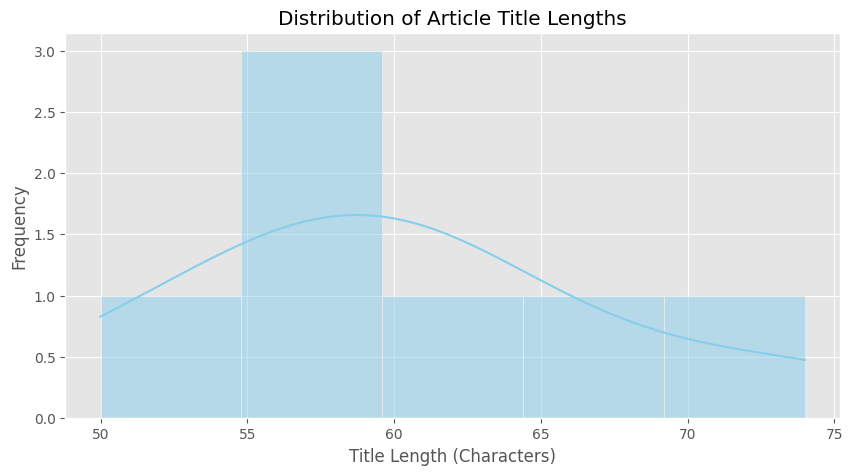

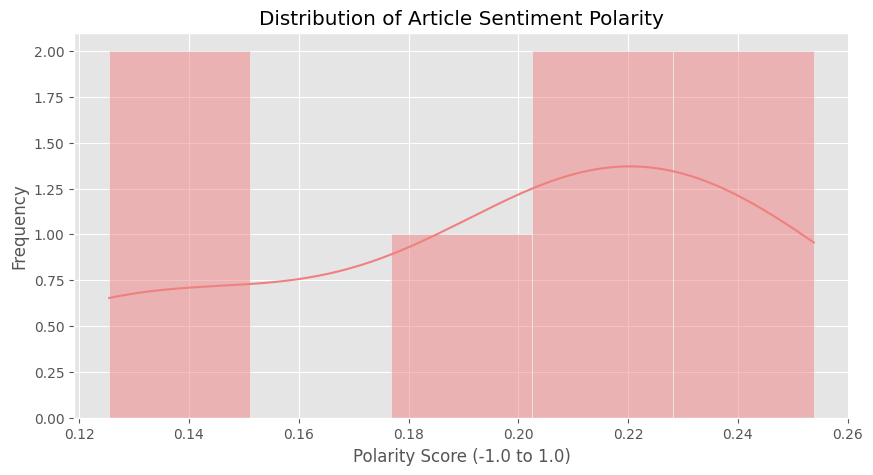

In [9]:
import os
os.makedirs('figures', exist_ok=True)
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# 1. Title Length Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['title_length'], kde=True, bins=5, color='skyblue')
plt.title('Distribution of Article Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Frequency')
plt.savefig('figures/fig1_title_length.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Sentiment Polarity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['sentiment_polarity'], kde=True, bins=5, color='lightcoral')
plt.title('Distribution of Article Sentiment Polarity')
plt.xlabel('Polarity Score (-1.0 to 1.0)')
plt.ylabel('Frequency')
plt.savefig('figures/fig2_sentiment_polarity.png', dpi=150, bbox_inches='tight')
plt.show()

## B. Pairwise relationships between the derived numeric features

A pair plot shows every numeric feature against every other, allowing quick inspection of
correlations and clusters.

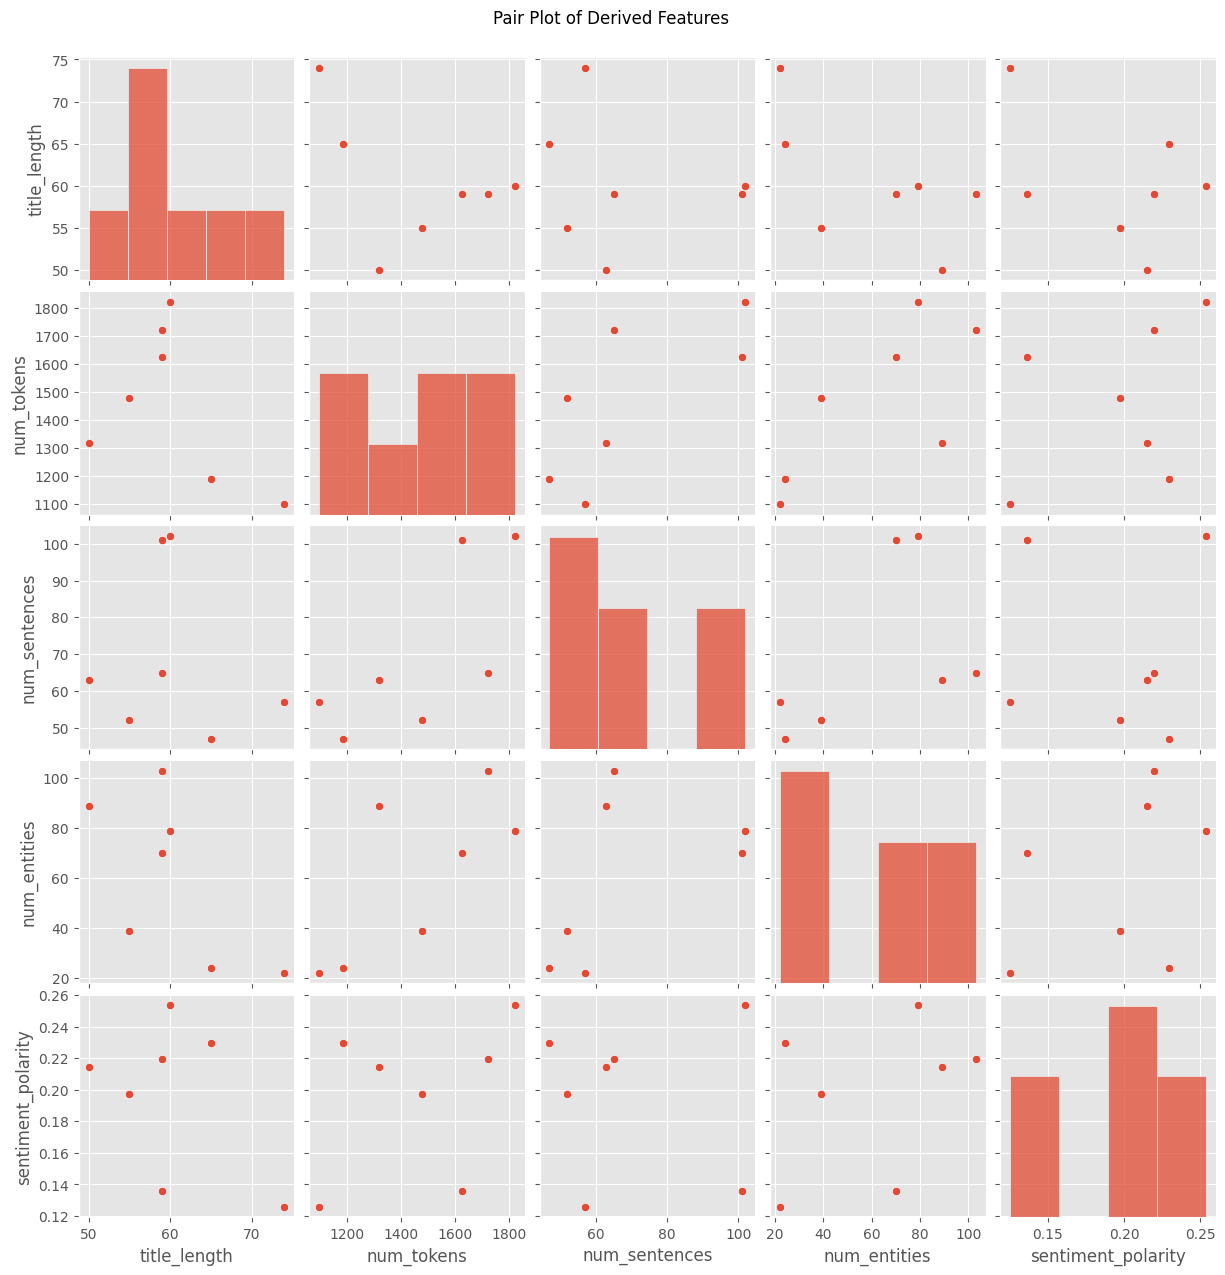

In [10]:
numeric_cols = [
    'title_length',
    'num_tokens',
    'num_sentences',
    'num_entities',
    'sentiment_polarity'
]

sns.pairplot(df[numeric_cols])
plt.suptitle('Pair Plot of Derived Features', y=1.02)
plt.savefig('figures/fig3_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# The same information as numbers. With five articles this is indicative only.
print("Correlation matrix:\n")
display(df[numeric_cols].corr().round(2))

Correlation matrix:



,title_length,num_tokens,num_sentences,num_entities,sentiment_polarity
title_length,1.00,-0.44,-0.16,-0.64,-0.45
num_tokens,-0.44,1.00,0.72,0.73,0.39
num_sentences,-0.16,0.72,1.00,0.50,-0.02
num_entities,-0.64,0.73,0.50,1.00,0.37
sentiment_polarity,-0.45,0.39,-0.02,0.37,1.00


## C. Advanced text feature — TF–IDF analysis

**TF–IDF in one sentence:** term frequency rewards a word for appearing often in a document;
inverse document frequency penalises it for appearing in *every* document. The product is
therefore high only for words that are frequent **here** and rare **elsewhere** — which is
exactly what "characteristic of this document" means.

| Code | Explanation |
|---|---|
| `TfidfVectorizer(...)` | `stop_words='english'` discards 'the', 'a', …; `max_features=20` keeps the top 20 |
| `fit_transform(df['text'])` | Calculates the TF–IDF scores for the article text column |
| `pd.DataFrame(X.toarray(), ...)` | Converts the sparse matrix into a readable DataFrame |
| `tfidf_df.sum().sort_values(...)` | Sums scores across all documents to rank global importance |

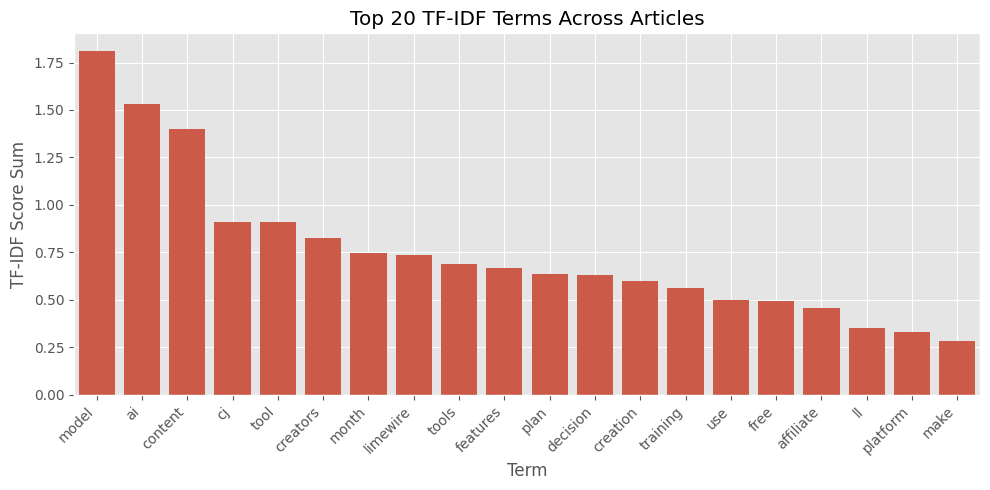

Sparse matrix shape (documents x terms): (7, 20)


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# stop_words='english' discards 'the', 'a', ...; max_features keeps the top 20
vectorizer = TfidfVectorizer(stop_words='english', max_features=20)

X = vectorizer.fit_transform(df['text'])
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Sum each term's score across all documents to rank global importance
tfidf_sums = tfidf_df.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=tfidf_sums.index, y=tfidf_sums.values)
plt.title("Top 20 TF-IDF Terms Across Articles")
plt.ylabel("TF-IDF Score Sum")
plt.xlabel("Term")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.savefig('figures/fig4_tfidf_top20.png', dpi=150, bbox_inches='tight')
plt.show()

print("Sparse matrix shape (documents x terms):", X.shape)

---
# In-Lab Exercises

Complete all four during the session.

**Exercise 1.** Add two URLs of your own choosing to the list. Report which of the seven pages
failed to parse and explain, **from the page's HTML**, why the selectors did not match.

**Exercise 2.** Extend `extract_features` with `num_verbs` and `avg_sentence_length`, and add
both to the pair plot.

**Exercise 3.** The polarity histogram is computed over five articles. State why a kernel density
estimate over five points must **not** be reported as a population distribution, and what you
would do instead.

**Exercise 4.** Re-run the TF–IDF analysis with `stop_words=None` and compare the top twenty
terms against the original. Explain the difference.

,title,num_tokens,num_sentences,num_entities,num_nouns,num_verbs,avg_sentence_length
0,Top 10 AI Tools That Will Transform Your Conte...,1188.0,47.0,24.0,321.0,150.0,25.276596
1,"LimeWire AI Studio Review 2023: Details, Prici...",1723.0,65.0,103.0,420.0,200.0,26.507692
2,Top 10 AI Tools in 2023 That Will Make Your Li...,1480.0,52.0,39.0,331.0,166.0,28.461538
3,Top 10 AI Content Generator & Writer Tools in ...,1319.0,63.0,89.0,271.0,140.0,20.936508
4,Beginner Guide to CJ Affiliate (Commission Jun...,1822.0,102.0,79.0,391.0,206.0,17.862745
5,How to Train Your own Decision Model like Jev ...,1627.0,101.0,70.0,394.0,204.0,16.108911
6,Choosing an LLM Inference Optimization Techniq...,1098.0,57.0,22.0,259.0,149.0,19.263158


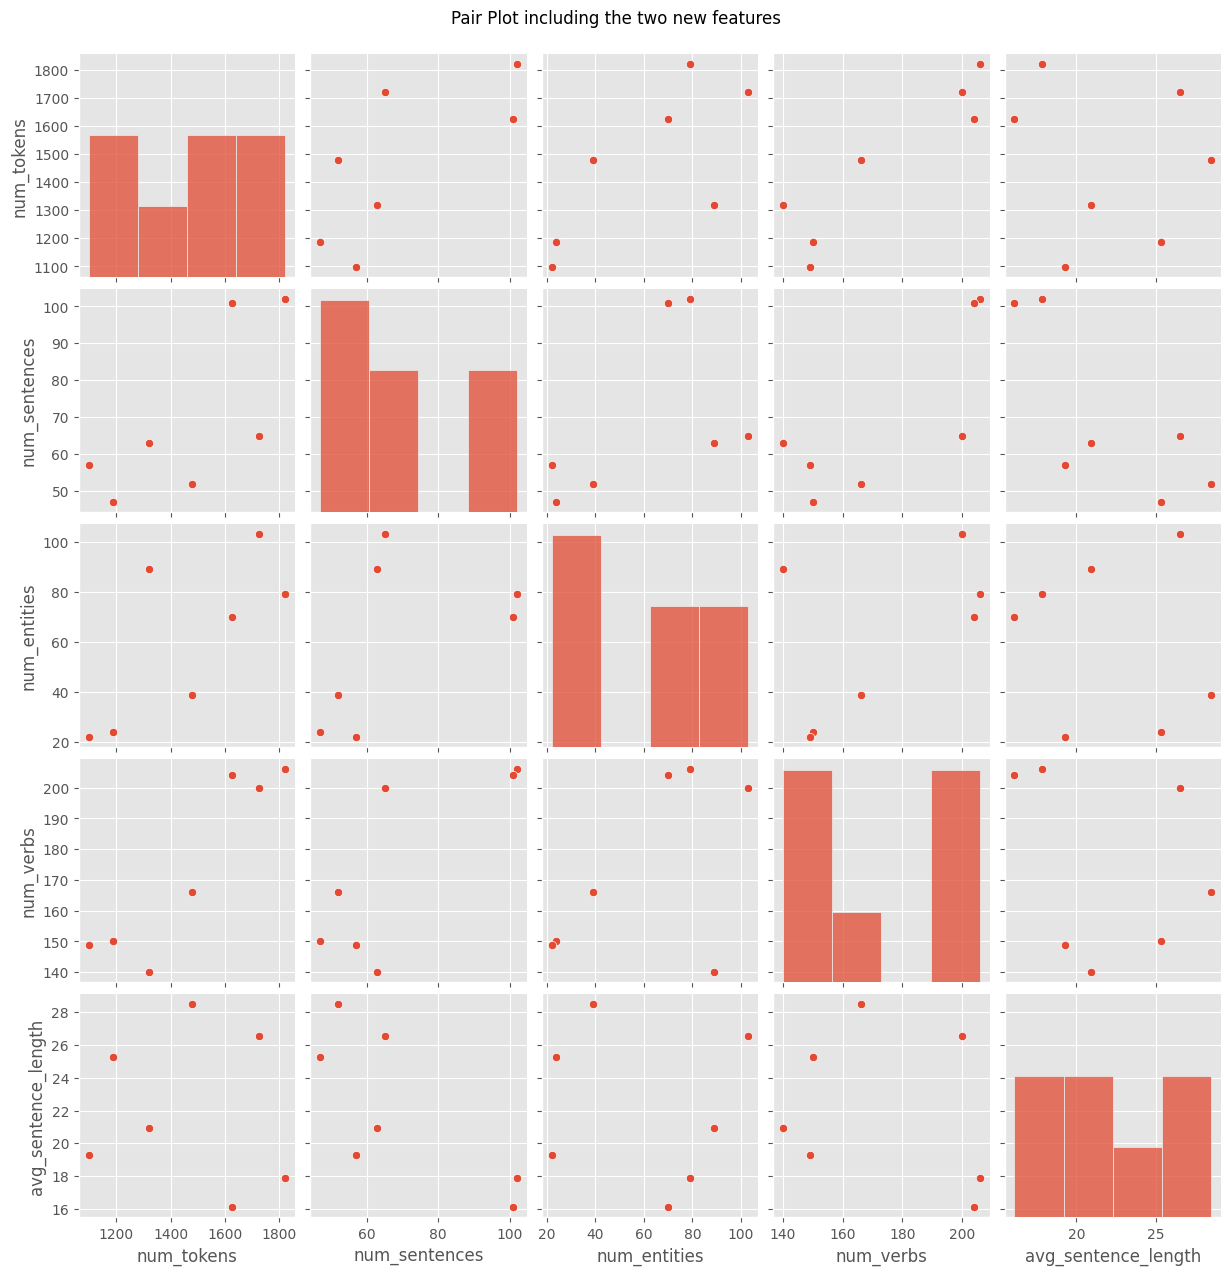

In [13]:
# --- Exercise 2: extended feature extraction -----------------------------

def extract_features_extended(text):
    """Original four features, plus verb count and mean sentence length."""
    doc = nlp(text)
    sentences = list(doc.sents)
    return pd.Series({
        'num_tokens':          len(doc),
        'num_sentences':       len(sentences),
        'num_entities':        len(doc.ents),
        'num_nouns':           len([t for t in doc if t.pos_ == 'NOUN']),
        'num_verbs':           len([t for t in doc if t.pos_ == 'VERB']),
        'avg_sentence_length': (len(doc) / len(sentences)) if sentences else 0.0,
    })


extended = df['text'].apply(extract_features_extended)
df_ext = pd.concat([df[['title']], extended], axis=1)
display(df_ext)

sns.pairplot(df_ext[['num_tokens', 'num_sentences', 'num_entities',
                     'num_verbs', 'avg_sentence_length']])
plt.suptitle('Pair Plot including the two new features', y=1.02)
plt.savefig('figures/fig5_pairplot_extended.png', dpi=150, bbox_inches='tight')
plt.show()

**Your answer to Exercise 1** (why did one page fail?):

The page `cj-affiliate-ultimate-guide-to.html` was skipped with `[SKIP] Too short`. I checked its HTML: the status was 200, the content `div` (`post-body entry-content`) **was found**, but it contained **0 `<p>` tags** (0 characters from `<p>`, 9,350 characters from the whole div). The article text is written directly inside the `<div>` (after a `<table>` with an image), not in paragraphs. My code only collected `<p>` text, got an empty string, and the length check rejected the page. **Fix:** if the `<p>` text is under 100 characters, use `content_div.get_text(" ", strip=True)` instead. I also added two URLs of my own (the two newest posts from the Machine Learning Mastery feed) and a fallback to `<article>` / `<main>` for other layouts.


**Your answer to Exercise 2:** I added `num_verbs` and `avg_sentence_length` and included them in the pair plot (see the table and plot above). Longer articles tend to have more verbs, as expected. Average sentence length shows how long and complex the sentences are in each article.


In [14]:
# --- Exercise 4: TF-IDF with and without stop-word removal ---------------

vec_stop = TfidfVectorizer(stop_words='english', max_features=20)
vec_none = TfidfVectorizer(stop_words=None,      max_features=20)

top_stop = (pd.DataFrame(vec_stop.fit_transform(df['text']).toarray(),
                         columns=vec_stop.get_feature_names_out())
              .sum().sort_values(ascending=False))
top_none = (pd.DataFrame(vec_none.fit_transform(df['text']).toarray(),
                         columns=vec_none.get_feature_names_out())
              .sum().sort_values(ascending=False))

comparison = pd.DataFrame({
    "with stop_words='english'": top_stop.index,
    "with stop_words=None":      top_none.index,
})
display(comparison)

print("\nTerms that appear ONLY when stop words are kept:")
print(sorted(set(top_none.index) - set(top_stop.index)))

,with stop_words='english',with stop_words=None
0,model,the
1,ai,and
2,content,to
3,cj,for
4,tool,of
5,creators,it
6,month,ai
7,limewire,you
8,tools,content
9,features,is



Terms that appear ONLY when stop words are kept:
['and', 'as', 'can', 'for', 'in', 'is', 'it', 'of', 'on', 'that', 'the', 'this', 'to', 'with', 'you', 'your']


**Your answer to Exercise 4** (TF-IDF with and without stop words):

With `stop_words='english'` the top terms are real topic words (for example `content`, `ai`, `tool`). With `stop_words=None` the top terms are function words such as `and`, `the`, `to`, `for`, `of`. Stop words appear in every document, so their IDF is low, but with only a few documents the IDF effect is weak and their very high counts still push them to the top. They say nothing about the topic, so removing them gives much more useful results.


**Your answer to Exercise 3** (why a KDE over five points is not a population distribution):

A KDE draws a smooth curve from the data. With only a handful of points, the shape of the curve is decided mostly by the bandwidth setting and not by real data, so it looks like a proper distribution but can be very wrong. One more article could change its shape a lot. Instead, I would collect many more articles (at least 30 to 50), show the raw points or a simple histogram, and report the mean with a range, saying clearly that the sample is small.

---


---
# Home Assignment

Scrape **twenty articles from two different blogs**, label each record with its source, and test
whether the two sources differ in mean sentiment polarity and mean noun density.

Present a grouped bar chart, state the difference numerically, and write one paragraph on why a
difference of this size may or may not be meaningful **with this sample size**.

Commit the notebook, the scraped CSV and the report.

ai-news: found 20 links in https://techcrunch.com/category/artificial-intelligence/feed/
  kept 10 articles from ai-news

machinelearningmastery: found 10 links in https://machinelearningmastery.com/blog/feed/
  kept 10 articles from machinelearningmastery

Total scraped: 20
source
ai-news                   10
machinelearningmastery    10
Name: count, dtype: int64

Summary per source:


polarity               noun_density              
                           mean     std count         mean     std count
source                                                                  
ai-news                  0.1258  0.0499    10        0.196  0.0191    10
machinelearningmastery   0.0958  0.0396    10        0.246  0.0235    10


Polarity     : ai-news = 0.1258, machinelearningmastery = 0.0958, difference = +0.0300
Noun density : ai-news = 0.1960, machinelearningmastery = 0.2460, difference = -0.0500
  t-test on polarity: p = 0.1549
  t-test on noun_density: p = 0.0001


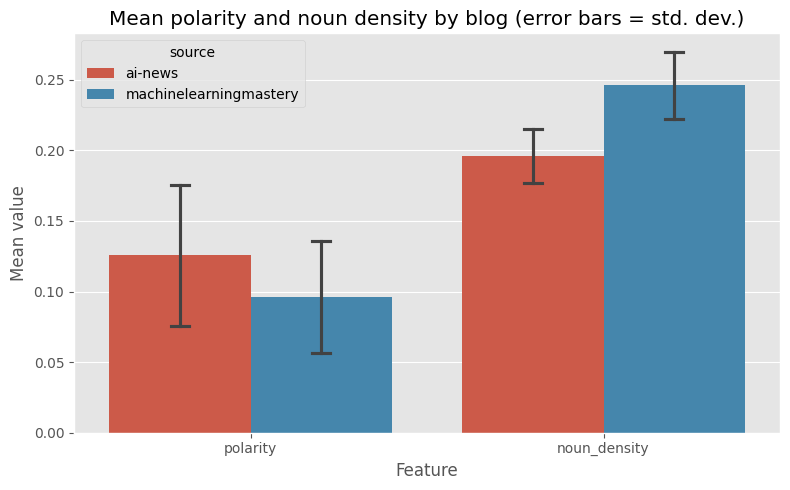

In [16]:
# ============================================================
# HOME ASSIGNMENT: compare 2 blogs (10 articles each)
# Paste this whole cell into Colab AFTER the earlier cells have run
# (it needs: requests, BeautifulSoup, pandas, spacy `nlp`, TextBlob).
# ============================================================
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from textblob import TextBlob

# ---- 1. Choose your two blogs (you can change these) -------
# Each blog has a "feed" URL. A feed is a list of the latest posts,
# so we do not need to type article URLs by hand.
#
# NOTE: the old techncruncher blog now redirects to crunchhype.com, which
# Colab cannot connect to. So we use feeds that work. For each blog we give
# a list of feeds; the code uses the first one that works.
SOURCES = [
    {"name": "ai-news",
     "feeds": ["https://techcrunch.com/category/artificial-intelligence/feed/",
               "https://www.artificialintelligence-news.com/feed/"]},
    {"name": "machinelearningmastery",
     "feeds": ["https://machinelearningmastery.com/blog/feed/"]},
]
ARTICLES_PER_SOURCE = 10

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}


# ---- 2. Get article URLs from a feed -----------------------
def get_urls_from_feed(feed_url, limit=15):
    """Return article links from an RSS or Atom feed."""
    res = requests.get(feed_url, headers=headers, timeout=15)
    res.raise_for_status()
    soup = BeautifulSoup(res.content, "xml")
    urls = []

    # Atom feed (Blogspot): <entry><link rel="alternate" href="...">
    for entry in soup.find_all("entry"):
        link = entry.find("link", rel="alternate")
        if link and link.get("href"):
            urls.append(link["href"])

    # RSS feed (WordPress): <item><link>...</link>
    for item in soup.find_all("item"):
        link = item.find("link")
        if link and link.get_text(strip=True):
            urls.append(link.get_text(strip=True))

    return urls[:limit]


# ---- 3. Scrape one article (works on many blog layouts) ----
def scrape_article(url):
    """Return (title, text) or None if the page has too little text."""
    res = requests.get(url, headers=headers, timeout=15)
    res.raise_for_status()
    soup = BeautifulSoup(res.content, "lxml")

    # Title: try the page's <h1>, then <h3 class="post-title">, then <title>
    t = soup.find("h1") or soup.find("h3", class_="post-title") or soup.title
    title = t.get_text(strip=True) if t else url

    # Body: try known containers first, then fall back to <article> / <main>
    block = (soup.find("div", class_="post-body")
             or soup.find("article")
             or soup.find("main")
             or soup.body)
    if block is None:
        return None

    # Use <p> tags; if there are almost none (like the page that failed in
    # Exercise 1), use all the text in the block instead.
    text = " ".join(p.get_text(" ", strip=True) for p in block.find_all("p"))
    if len(text) < 300:
        text = block.get_text(" ", strip=True)

    return (title, text) if len(text) > 300 else None


# ---- 4. Scrape both sources politely ------------------------
rows = []
for src in SOURCES:
    kept = 0
    for feed in src["feeds"]:
        if kept >= ARTICLES_PER_SOURCE:
            break
        try:
            urls = get_urls_from_feed(feed, limit=20)
        except Exception as e:
            print(f"[ERROR] Could not read feed {feed}: {str(e)[:100]}")
            continue

        print(f"{src['name']}: found {len(urls)} links in {feed}")
        failures = 0
        for url in urls:
            if kept >= ARTICLES_PER_SOURCE:
                break
            if failures >= 3:   # site seems unreachable: try the next feed
                print("  Too many errors, moving on.")
                break
            try:
                result = scrape_article(url)
                if result is None:
                    print(f"  [SKIP] too little text: {url}")
                else:
                    title, text = result
                    rows.append({"source": src["name"], "url": url,
                                 "title": title, "text": text})
                    kept += 1
                    failures = 0
            except Exception as e:
                failures += 1
                print(f"  [ERROR] {url} -> {str(e)[:100]}")
            time.sleep(1)          # be polite to the server

    print(f"  kept {kept} articles from {src['name']}\n")

df_hw = pd.DataFrame(rows)
df_hw.to_csv("home_assignment_raw.csv", index=False)
print("Total scraped:", len(df_hw))
print(df_hw["source"].value_counts())


# ---- 5. Features: polarity and noun density ----------------
MAX_CHARS = 100_000  # keep spaCy fast and inside its length limit

def noun_density(text):
    doc = nlp(text[:MAX_CHARS])
    nouns = sum(1 for t in doc if t.pos_ == "NOUN")
    return nouns / len(doc) if len(doc) else 0.0

df_hw["polarity"] = df_hw["text"].apply(lambda t: TextBlob(t).sentiment.polarity)
df_hw["noun_density"] = df_hw["text"].apply(noun_density)
df_hw.to_csv("home_assignment_features.csv", index=False)


# ---- 6. Compare the two sources -----------------------------
summary = df_hw.groupby("source")[["polarity", "noun_density"]].agg(["mean", "std", "count"]).round(4)
print("\nSummary per source:")
display(summary)

means = df_hw.groupby("source")[["polarity", "noun_density"]].mean()
if len(means) == 2:
    a, b = means.index
    print(f"\nPolarity     : {a} = {means.loc[a,'polarity']:.4f}, "
          f"{b} = {means.loc[b,'polarity']:.4f}, "
          f"difference = {means.loc[a,'polarity'] - means.loc[b,'polarity']:+.4f}")
    print(f"Noun density : {a} = {means.loc[a,'noun_density']:.4f}, "
          f"{b} = {means.loc[b,'noun_density']:.4f}, "
          f"difference = {means.loc[a,'noun_density'] - means.loc[b,'noun_density']:+.4f}")

    # Optional: Welch t-test (tells us if the difference could be chance)
    from scipy import stats
    for col in ["polarity", "noun_density"]:
        g1 = df_hw.loc[df_hw.source == a, col]
        g2 = df_hw.loc[df_hw.source == b, col]
        t_stat, p_val = stats.ttest_ind(g1, g2, equal_var=False)
        print(f"  t-test on {col}: p = {p_val:.4f}")


# ---- 7. Grouped bar chart ------------------------------------
plot_df = (df_hw.melt(id_vars="source", value_vars=["polarity", "noun_density"],
                      var_name="feature", value_name="value"))
plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="feature", y="value", hue="source", errorbar="sd", capsize=0.1)
plt.title("Mean polarity and noun density by blog (error bars = std. dev.)")
plt.xlabel("Feature")
plt.ylabel("Mean value")
plt.tight_layout()
plt.savefig("home_assignment_chart.png", dpi=150)
plt.show()


In [18]:
# --- Pack all deliverables into lab02.zip and download it --------------------
import os, shutil
from google.colab import files

os.makedirs('lab02/figures', exist_ok=True)
for f in os.listdir('figures'):
    shutil.copy(os.path.join('figures', f), 'lab02/figures')
for f in ['articles.csv', 'articles_raw.csv', 'home_assignment_raw.csv',
          'home_assignment_features.csv', 'home_assignment_chart.png']:
    if os.path.exists(f):
        shutil.copy(f, 'lab02')

shutil.make_archive('lab02', 'zip', '.', 'lab02')
print("Files in lab02:", os.listdir('lab02'))
files.download('lab02.zip')


Files in lab02: ['articles_raw.csv', 'articles.csv', 'home_assignment_raw.csv', 'figures', 'home_assignment_features.csv', 'home_assignment_chart.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Deliverables

| File | Contents |
|---|---|
| `lab02/scraping_eda.ipynb` | This notebook, executed, with all outputs visible |
| `lab02/articles.csv` | The scraped corpus with all engineered features |
| `lab02/figures/*.png` | The four figures exported as PNG |
| `lab02/report.md` | The NumPy timing comparison, the EDA findings and the TF–IDF interpretation |

## Assessment Rubric

| Criterion | Weight | Excellent performance |
|---|---|---|
| Correctness of implementation | 35 % | Scraper handles failures gracefully; features computed correctly |
| Methodological soundness | 25 % | Server treated politely; sample-size limits acknowledged |
| Analysis and interpretation | 20 % | Figures are *read*, not merely produced |
| Code quality and reproducibility | 10 % | Raw scrape cached; functions reusable |
| Report and demonstration | 10 % | Clear written report and working demonstration |

---

**Next laboratory:** Lab 03 — Transforming Textual and Image Data into a Machine-Understandable Format.